In [1]:
# conda env at3d_metpy
"""Generates optical properties of the molecular atmosphere 
based on ERA5 reanalysis.

Generates ATMOS*.nc
"""

import xarray as xr
import numpy as np
import at3d
import matplotlib.pyplot as plt

from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'

In [2]:
## INPUT
# RT Grid
rte_grid_file = INTERIM_DATA / 'RTG_default.nc'
rte_grid = xr.load_dataset(rte_grid_file)
# ERA Upper
era_upper_file = RAW_DATA / 'era5' / 'ERA5_upper_CAMP2Ex_RF17_wide.nc'
era_upper = xr.load_dataset(era_upper_file)
# ERA surface
era_surf_file = RAW_DATA / 'era5' / 'ERA5_surface_CAMP2Ex_RF17_wide_extra.nc'
era_surf = xr.load_dataset(era_surf_file)
# Wavelength
wavelength = 0.67

## OUTPUT
out_file = INTERIM_DATA / 'ATMOS_ERA5_CAMP2Ex_RF17_default.nc'

In [3]:
interp_time = [np.datetime64('2019-10-02T02:33:00')]
interp_lat = 19.6
interp_lon = 120.75

era_upper_interp = era_upper.interp(valid_time=interp_time).isel(valid_time=0)
era_upper_interp = era_upper_interp.interp(latitude = interp_lat)
era_upper_interp = era_upper_interp.interp(longitude = interp_lon)
era_surf_interp = era_surf.interp(valid_time=interp_time).isel(valid_time=0)
era_surf_interp = era_surf_interp.interp(latitude = interp_lat)
era_surf_interp = era_surf_interp.interp(longitude = interp_lon)

In [4]:
era_upper_interp

<xarray.Dataset>
Dimensions:         (pressure_level: 37)
Coordinates:
  * pressure_level  (pressure_level) float64 1e+03 975.0 950.0 ... 3.0 2.0 1.0
    valid_time      datetime64[s] 2019-10-02T02:33:00
    latitude        float64 19.6
    longitude       float64 120.8
Data variables: (12/18)
    number          int64 0
    d               (pressure_level) float64 1.698e-06 1.504e-06 ... 1.011e-06
    cc              (pressure_level) float64 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    z               (pressure_level) float64 1.16e+03 3.356e+03 ... 4.687e+05
    o3              (pressure_level) float64 5.936e-08 5.973e-08 ... 4.952e-06
    pv              (pressure_level) float64 -6.448e-09 7e-08 ... 0.002363
    ...              ...
    t               (pressure_level) float64 300.0 297.8 297.6 ... 264.4 262.8
    u               (pressure_level) float64 0.532 0.5159 0.08933 ... 11.42 26.2
    v               (pressure_level) float64 0.6612 0.7111 ... 6.054 -2.245
    w               (pressure_level) float64 -0.009069 -0.00542 ... 2.202e-05
    vo              (pressure_level) float64 -2.058e-05 -2.006e-05 ... 5.144e-06
    expver          object '0001'
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-08-21T14:03 GRIB to CDM+CF via cfgrib-0.9.1...

In [5]:
Re = 6.371e6 # m
g = 9.80665 # m s^-2
Phi = era_upper_interp.z.data
z = (Phi * Re) / (g * Re - Phi)
z *= 1e-3

In [6]:
T = np.append([era_surf_interp.t2m.data], era_upper_interp.t.data)
P = np.append([era_surf_interp.sp.data*1e-2], era_upper_interp.pressure_level.data)
z = np.append([0], z)

atmosphere = xr.Dataset(
    data_vars={
        'temperature': (['z'], T),
        'pressure': (['z'], P)
    },
    coords={
        'z': z
    }
)

atmosphere_optical_properties = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid)

In [7]:
"""
Account for the molecular atmosphere above the domain by changing the extinction in the top layer.
This algorithm ensures that the 'compensated' optical depth agrees with the 'exact' optical depth.
"""
rte_grid_exact = rte_grid.copy(deep=True)
rte_grid_exact['z'] = atmosphere.z
atmosphere_optical_properties_exact = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid_exact)
tau_exact = atmosphere_optical_properties_exact[wavelength].isel(x=0,y=0).extinction.integrate('z').data

rte_grid_minus1 = rte_grid.copy(deep=True)
rte_grid_minus1['z'] = rte_grid.z[:-1]
atmosphere_optical_properties_minus1 = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid_minus1)
tau_minus1 = atmosphere_optical_properties_minus1[wavelength].isel(x=0,y=0).extinction.integrate('z').data

del_tau = tau_exact - tau_minus1
h = rte_grid.z.data[-1] - rte_grid.z.data[-2]
xmax = atmosphere_optical_properties_minus1[wavelength].isel(x=0,y=0, z=-1).extinction.data
compensation_extinction = ((2*del_tau)/h) - xmax
atmosphere_optical_properties_comp = {}
atmosphere_optical_properties_comp[wavelength] = atmosphere_optical_properties[wavelength].copy(deep=True)
extinction = atmosphere_optical_properties[wavelength].extinction.copy(deep=True).data
extinction[:,:,-1] = compensation_extinction
atmosphere_optical_properties_comp[wavelength]['extinction'] = (['x','y','z'], extinction)

tau_exact:  0.04357
tau_comp:   0.04357
tau:        0.00648
tau minus1: 0.00604


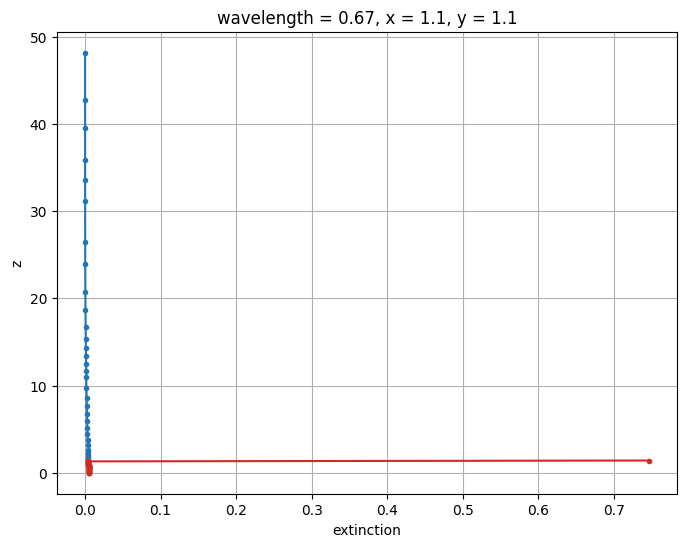

In [8]:
# PLOT CORRECTED EXTINCTION
f, ax = plt.subplots(1, 1, figsize=(8,6))
atmosphere_optical_properties_exact[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties_minus1[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties_comp[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
ax.grid()
tau_exact = atmosphere_optical_properties_exact[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau_comp = atmosphere_optical_properties_comp[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau = atmosphere_optical_properties[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau_minus1 = atmosphere_optical_properties_minus1[wavelength].isel(x=4,y=4).extinction.integrate('z').data
print('tau_exact:  {:.5f}'.format(tau_exact))
print('tau_comp:   {:.5f}'.format(tau_comp))
print('tau:        {:.5f}'.format(tau))
print('tau minus1: {:.5f}'.format(tau_minus1))